**For generating plots using Wandb csv.file**

In [81]:

import pandas as pd
import matplotlib.pyplot as plt
import os

def find_column(df, keyword, metric_type='episode_reward', exclude=None):
    """
    keyword가 포함된 컬럼을 찾되, exclude 키워드가 있다면 제외하는 함수.
    특정 환경 이름(env term) 없이도 모델을 구별할 수 있게 해줍니다.
    """
    target_pattern = f'mean_{metric_type}'
    
    for col in df.columns:
        if keyword in col and target_pattern in col:
            if 'MIN' in col or 'MAX' in col or '_step' in col:
                continue
            
            # 3. 제외 키워드(exclude) 확인 (예: 'mappo' 찾을 때 'pci' 제외)
            if exclude and exclude in col:
                continue
                
            return col
    return None

def plot(df_reward, df_length, models_config, window_size=50, font_size=15):

    # --- Plot 1: Reward ---
    plt.figure(figsize=(8,6))
    for label, config in models_config.items():
        kw = config['keyword']
        exc = config.get('exclude') # exclude 키워드가 없으면 None
        color = config['color']
        col = find_column(df_reward, kw, 'episode_reward', exclude=exc)
        if col:
            x = df_reward['total_steps']
            y = df_reward[col]
            
            y_mean = y.rolling(window=window_size, min_periods=1).mean()
            y_std = y.rolling(window=window_size, min_periods=1).std()
            
            plt.plot(x, y_mean, label=label, color=color, linewidth=2)
            plt.fill_between(x, y_mean - y_std, y_mean + y_std, color=color, alpha=0.2)

    plt.title(f'Mean Episode Return', fontsize=font_size)
    plt.xlabel('Total Steps', fontsize=font_size)
    plt.ylabel('Mean Episode Return', fontsize=font_size)
    plt.legend(loc='lower right', fontsize=font_size)
    plt.grid(True, linestyle='--', alpha=0.5)

    # --- Plot 2: Success Rate ---
    plt.figure(figsize=(8,6))
    for label, config in models_config.items():
        kw = config['keyword']
        exc = config.get('exclude')
        color = config['color']
        
        col = find_column(df_length, kw, 'success_rate', exclude=exc)
        if col:
            x = df_length['total_steps']
            y = df_length[col]
            
            y_mean = y.rolling(window=window_size, min_periods=1).mean()
            y_std = y.rolling(window=window_size, min_periods=1).std()
            
            plt.plot(x, y_mean, label=label, color=color, linewidth=2)
            plt.fill_between(x, y_mean - y_std, y_mean + y_std, color=color, alpha=0.2)

    plt.title(f'Success Rate', fontsize=font_size)
    plt.xlabel('Total Steps', fontsize=font_size)
    plt.ylabel('Success Rate', fontsize=font_size)
    plt.legend(loc='lower right', fontsize=font_size)
    plt.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

def plot_causal_effect(file_path, window_size=50):
    try:
        df = pd.read_csv(file_path)
    except FileNotFoundError:
        print(f'File not found: {file_path}')
        return

    # Determine the reward type based on available columns
    reward_type = None
    target_cols = []
    
    # Check for stag reward
    stag_cols = [c for c in df.columns if 'delta_stag_reward' in c and 'agent' in c and 'MIN' not in c and 'MAX' not in c]
    if stag_cols:
        reward_type = 'Stag'
        target_cols = stag_cols
    else:
        # Check for forage reward
        forage_cols = [c for c in df.columns if 'delta_forage_reward' in c and 'agent' in c and 'MIN' not in c and 'MAX' not in c]
        if forage_cols:
            reward_type = 'Forage'
            target_cols = forage_cols
    
    if not target_cols:
        print(f'No suitable columns (delta_stag_reward or delta_forage_reward) found in {file_path}')
        return

    print(f"Plotting {reward_type} Causal Effect from: {file_path}")
    print(f"Found columns: {len(target_cols)}")

    # Calculate mean across agents by row
    df['mean_agent_reward'] = df[target_cols].mean(axis=1)
    
    x = df['total_steps']
    y = df['mean_agent_reward']
    
    # Calculate rolling stats
    y_mean = y.rolling(window=window_size, min_periods=1).mean()
    y_std = y.rolling(window=window_size, min_periods=1).std()
    
    plt.figure(figsize=(10, 6))
    plt.plot(x, y_mean, label=f'Average $\delta$_{reward_type}', linewidth=2)
    plt.fill_between(x, y_mean - y_std, y_mean + y_std, alpha=0.2)
    plt.title(f'Causal Effect: Average $\delta$_{reward_type} over agents')
    plt.ylim(bottom=0)
    plt.xlabel('Total Steps')
    plt.ylabel(f'Delta {reward_type} Reward')
    plt.legend()
    plt.grid(True, linestyle= '--', alpha=0.5)
    plt.show()


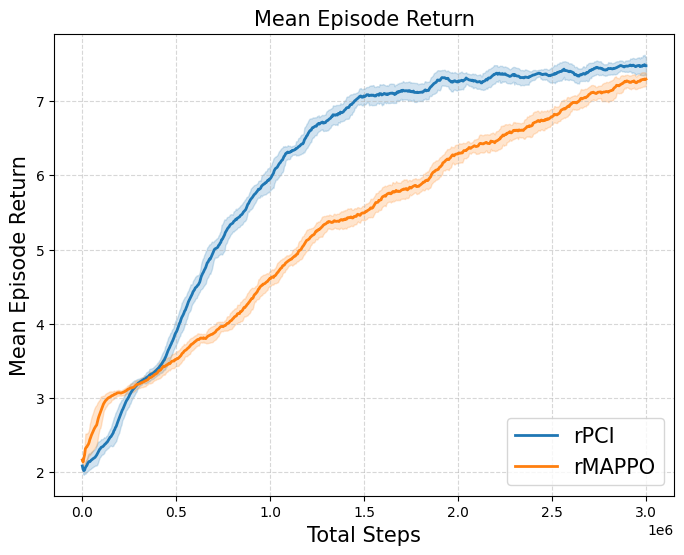

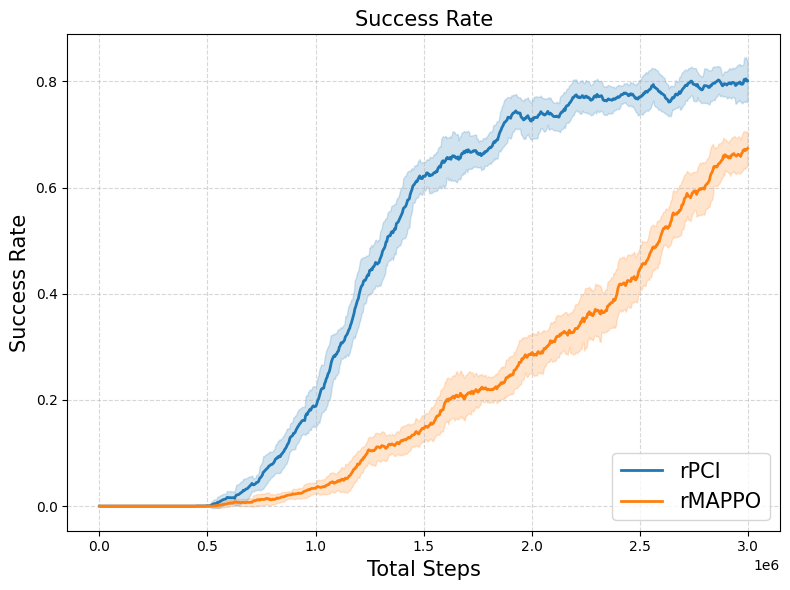

File not found: wandb_csv/sh3_stag_causal_effect.csv
File not found: wandb_csv/sh3_forage_causal_effect.csv


In [82]:
# 데이터 로드
csv_dir = 'wandb_csv'
reward_file = os.path.join(csv_dir, 'sh3_episode_return.csv')
length_file = os.path.join(csv_dir, 'sh3_success_rate.csv')
df_reward = pd.read_csv(reward_file)
df_length = pd.read_csv(length_file)

# 모델 설정: 'exclude' 옵션을 사용하여 특정 환경 이름 없이 구분
models_config = {
    "rPCI": {"keyword": "rPCI", "color": "tab:blue"},
    "rMAPPO":     {"keyword": "rMAPPO", "exclude": "pci", "color": "tab:orange"}, # 'pci'가 없는 'mappo'만 선택
    # "IPPO":      {"keyword": "rippo", "color": "tab:green"},
}

# Plotting
plot(df_reward, df_length, models_config, window_size=20, font_size=15)
plot_causal_effect('wandb_csv/sh3_stag_causal_effect.csv')
plot_causal_effect('wandb_csv/sh3_forage_causal_effect.csv')